# 04 · Data integration and benchmarking

Three representations are compared:

| method | idea | input |
|---|---|---|
| **PCA** (unintegrated) | linear, no correction | scaled log-normalised HVGs |
| **Harmony** (Korsunsky *et al.* 2019) | iterative soft clustering in PC space; removes library-specific centroid shifts | PCA |
| **scVI** (Lopez *et al.* 2018) | variational autoencoder with negative-binomial likelihood; batch is a decoder covariate, so the latent space is batch-conditional | raw counts of HVGs |

They are scored with **scib-metrics** (Luecken *et al.* 2022, *Nat Methods*):
*batch correction* (iLISI, kBET, graph connectivity, PCR comparison, batch
silhouette) and *bio-conservation* (isolated labels, Leiden NMI/ARI,
cell-type silhouette, cLISI). The authors' published labels serve as an
**independent** ground truth (our own labels are not yet defined, and using
them would be circular). The batch unit is the 10x library.

In [1]:
import matplotlib.pyplot as plt
import scanpy as sc

from ipfatlas import integration
from ipfatlas.config import setup
from ipfatlas.plotting import (
    CONDITION_COLORS,
    embedding_scatter,
    figsize,
    palette_for,
    panel_label,
    save_figure,
    set_style,
)
from ipfatlas.utils import write_table

cfg, P = setup()
set_style(cfg["figures"]["font_size"])
FIG = P.figures / "04_integration"
TAB = P.tables / "04_integration"
I = cfg["integration"]
BATCH = I["batch_key"]
MODELS = P.processed / "models"

adata = sc.read_h5ad(P.interim / "discovery_norm.h5ad")
import torch

print("CUDA available:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
adata

CUDA available: True NVIDIA GeForce RTX 4070


AnnData object with n_obs × n_vars = 136437 × 24723
    obs: 'library_id', 'donor_id', 'diagnosis', 'status', 'site', 'author_celltype', 'author_compartment', 'author_qc_pass', 'cohort', 'chemistry', 'sex', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier_counts', 'outlier_genes', 'outlier_top20', 'outlier_mito', 'outlier_hard', 'qc_fail', 'scDblFinder_score', 'scDblFinder_class', 'scDblFinder_doublet', 'scrublet_score', 'scrublet_doublet', 'S_score', 'G2M_score', 'phase'
    var: 'gene_symbol', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'highly_variable_nbatches'
    uns: 'log

## 1. Harmony

In [2]:
adata.obsm["X_harmony"] = integration.run_harmony(adata, BATCH, theta=I["harmony"]["theta"])

03:07:45 | INFO | Harmony ...


2026-10-29 03:07:45,704 - harmonypy - INFO - Running Harmony (PyTorch on cuda)


2026-10-29 03:07:45,704 - harmonypy - INFO -   Parameters:


2026-10-29 03:07:45,705 - harmonypy - INFO -     max_iter_harmony: 20


2026-10-29 03:07:45,705 - harmonypy - INFO -     max_iter_kmeans: 20


2026-10-29 03:07:45,705 - harmonypy - INFO -     epsilon_cluster: 1e-05


... (21 outputs left out)

2026-10-29 03:07:57,064 - harmonypy - INFO - Iteration 10 of 20


2026-10-29 03:07:57,704 - harmonypy - INFO - Iteration 11 of 20


2026-10-29 03:07:58,326 - harmonypy - INFO - Converged after 11 iterations


03:07:58 | INFO | Harmony done in 12.6 s


## 2. scVI
The model sees raw counts of the 3,000 HVGs. Training stops early when the
validation ELBO stops improving.

W1029 03:08:02.492000 25376 site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


Seed set to 0


03:08:04 | INFO | scVI training ...


GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.
J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


Training:   0%|          | 0/300 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=300` reached.


03:17:06 | INFO | scVI training done in 542.8 s


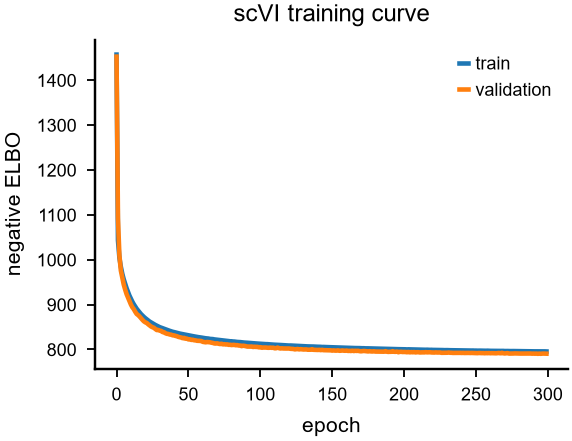

In [3]:
hv = adata[:, adata.var["highly_variable"]].copy()
model = integration.train_scvi(hv, BATCH, I["scvi"], layer="counts", save_dir=MODELS / "scvi_discovery")
adata.obsm["X_scVI"] = model.get_latent_representation()

hist = model.history
fig, ax = plt.subplots(figsize=figsize(70, 50))
ax.plot(hist["elbo_train"].index, hist["elbo_train"].values.ravel(), label="train")
if "elbo_validation" in hist:
    ax.plot(hist["elbo_validation"].index, hist["elbo_validation"].values.ravel(), label="validation")
ax.set_xlabel("epoch")
ax.set_ylabel("negative ELBO")
ax.set_title("scVI training curve")
ax.legend()
save_figure(fig, "S4_scvi_training_curve", FIG)
plt.show()

## 3. Benchmark with scib-metrics
Run on a random 40,000-cell subsample of cells that carry an author label.

In [4]:
lab = adata[adata.obs["author_celltype"].notna()].copy()
res = integration.benchmark(lab, BATCH, "author_celltype", ["X_pca", "X_harmony", "X_scVI"],
                            subsample=I["benchmark_subsample"], n_jobs=8)
write_table(res, TAB / "scib_metrics_benchmark")
res

03:17:15 | INFO | scib-metrics benchmark on 40,000 cells ...


Computing neighbors:   0%|          | 0/3 [00:00<?, ?it/s]

Computing neighbors:  33%|███▎      | 1/3 [00:18<00:36, 18.30s/it]

Computing neighbors:  67%|██████▋   | 2/3 [00:26<00:12, 12.31s/it]

Computing neighbors: 100%|██████████| 3/3 [00:33<00:00,  9.72s/it]

Computing neighbors: 100%|██████████| 3/3 [00:33<00:00, 11.02s/it]

... (64 outputs left out)

Embeddings: 100%|██████████| 3/3 [04:01<00:00, 80.65s/it]

03:21:50 | INFO | scib-metrics benchmark on 40,000 cells done in 275.2 s


INFO:ipfatlas:scib-metrics benchmark on 40,000 cells done in 275.2 s


,Isolated labels,KMeans NMI,KMeans ARI,Silhouette label,cLISI,BRAS,iLISI,KBET,Graph connectivity,PCR comparison,Batch correction,Bio conservation,Total
Embedding,,,,,,,,,,,,,
X_pca,0.642013,0.778896,0.479001,0.636063,1.0,0.672185,0.039947,0.568632,0.94372,0.0,0.444897,0.707194,0.602275
X_harmony,0.560285,0.774814,0.555118,0.630175,1.0,0.798394,0.080825,0.705754,0.881107,0.204787,0.534173,0.704078,0.636116
X_scVI,0.596408,0.71762,0.299673,0.553184,1.0,0.774925,0.062534,0.577087,0.916446,0.515302,0.569259,0.633377,0.60773
Metric Type,Bio conservation,Bio conservation,Bio conservation,Bio conservation,Bio conservation,Batch correction,Batch correction,Batch correction,Batch correction,Batch correction,Aggregate score,Aggregate score,Aggregate score


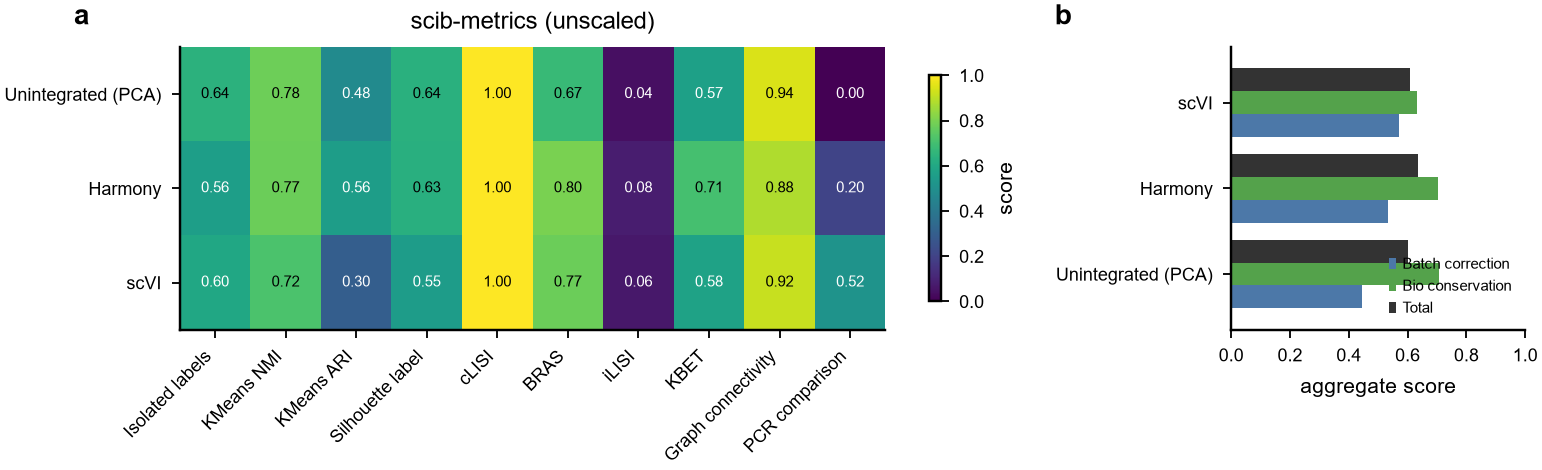

best overall representation: X_harmony


In [5]:
scores = res.drop(index="Metric Type", errors="ignore").astype(float)
mtype = res.loc["Metric Type"] if "Metric Type" in res.index else None
metrics = [c for c in scores.columns if c not in ("Batch correction", "Bio conservation", "Total")]
name_map = {"X_pca": "Unintegrated (PCA)", "X_harmony": "Harmony", "X_scVI": "scVI"}
scores.index = [name_map.get(i, i) for i in scores.index]

fig, axes = plt.subplots(1, 2, figsize=figsize(183, 60), gridspec_kw={"width_ratios": [3, 1]})
ax = axes[0]
im = ax.imshow(scores[metrics].values, cmap="viridis", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(metrics)))
ax.set_xticklabels(metrics, rotation=45, ha="right")
ax.set_yticks(range(len(scores)))
ax.set_yticklabels(scores.index)
for i in range(scores.shape[0]):
    for j, m in enumerate(metrics):
        ax.text(j, i, f"{scores.iloc[i][m]:.2f}", ha="center", va="center", fontsize=5,
                color="white" if scores.iloc[i][m] < 0.6 else "black")
plt.colorbar(im, ax=ax, shrink=0.8, label="score")
ax.set_title("scib-metrics (unscaled)")
panel_label(ax, "a", x=-0.15)
ax = axes[1]
agg = scores[["Batch correction", "Bio conservation", "Total"]]
agg.plot.barh(ax=ax, color=["#4C78A8", "#54A24B", "#333333"], width=0.8)
ax.set_xlim(0, 1)
ax.set_xlabel("aggregate score")
ax.legend(fontsize=5, loc="lower right")
panel_label(ax, "b", x=-0.6)
fig.tight_layout()
save_figure(fig, "S4_integration_benchmark", FIG)
plt.show()

best_key = {v: k for k, v in name_map.items()}[scores["Total"].idxmax()]
print("best overall representation:", best_key)

## 4. Visual comparison

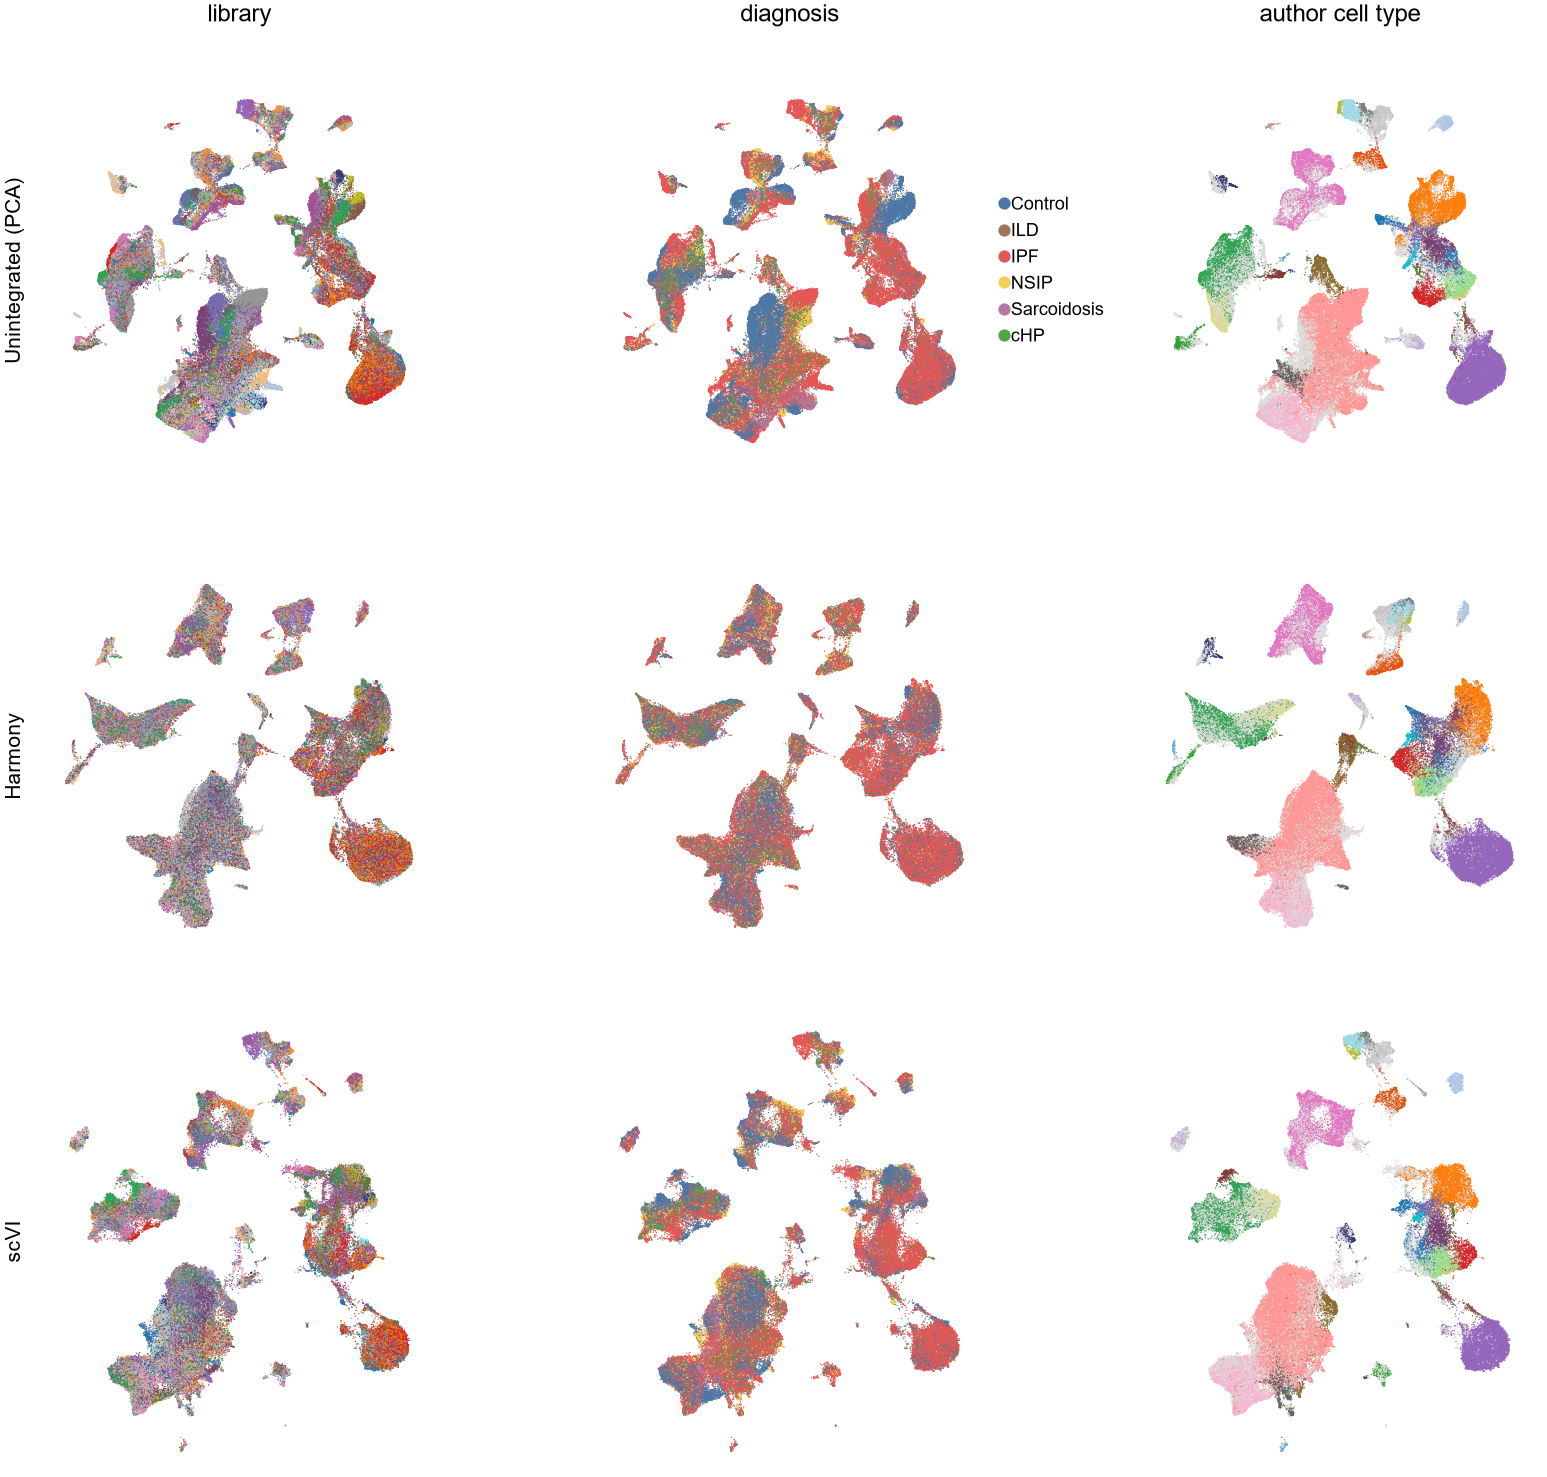

In [6]:
emb = {}
for key in ["X_pca", "X_harmony", "X_scVI"]:
    tmp = sc.AnnData(obs=adata.obs[[]].copy())
    tmp.obsm[key] = adata.obsm[key]
    sc.pp.neighbors(tmp, use_rep=key, n_neighbors=15, random_state=0)
    sc.tl.umap(tmp, min_dist=0.3, random_state=0)
    emb[key] = tmp.obsm["X_umap"]
    adata.obsm[f"X_umap_{key.replace('X_', '')}"] = tmp.obsm["X_umap"]

ac = adata.obs["author_celltype"].cat.add_categories("not in author set").fillna("not in author set")
ac_pal = palette_for(ac.cat.categories, {"not in author set": "#DDDDDD"})
fig, axes = plt.subplots(3, 3, figsize=figsize(183, 175))
for r, key in enumerate(["X_pca", "X_harmony", "X_scVI"]):
    embedding_scatter(axes[r, 0], emb[key], adata.obs[BATCH], s=0.2)
    embedding_scatter(axes[r, 1], emb[key], adata.obs["diagnosis"], palette=CONDITION_COLORS, s=0.2,
                      legend=(r == 0))
    embedding_scatter(axes[r, 2], emb[key], ac, palette=ac_pal, s=0.2)
    axes[r, 0].set_ylabel(name_map[key], fontsize=7)
    axes[r, 0].yaxis.set_visible(True)
    axes[r, 0].set_yticks([])
for c, t in enumerate(["library", "diagnosis", "author cell type"]):
    axes[0, c].set_title(t)
fig.tight_layout()
save_figure(fig, "S4_umap_methods_grid", FIG)
plt.show()

**Choice.** The representation with the best overall scib score is used for all
downstream neighbourhood-based steps (clustering, UMAP, trajectories). Note that
integrated embeddings are used *only* for these graph-based steps; differential
expression is always computed on raw counts with library/donor-aware models,
never on batch-corrected values.

In [7]:
adata.obsm["X_integrated"] = adata.obsm[best_key]
adata.uns["integration"] = {"method": best_key, "batch_key": BATCH}
adata.obsm["X_umap"] = adata.obsm[f"X_umap_{best_key.replace('X_', '')}"]
adata.write_h5ad(P.interim / "discovery_integrated.h5ad", compression="lzf")
adata

AnnData object with n_obs × n_vars = 136437 × 24723
    obs: 'library_id', 'donor_id', 'diagnosis', 'status', 'site', 'author_celltype', 'author_compartment', 'author_qc_pass', 'cohort', 'chemistry', 'sex', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier_counts', 'outlier_genes', 'outlier_top20', 'outlier_mito', 'outlier_hard', 'qc_fail', 'scDblFinder_score', 'scDblFinder_class', 'scDblFinder_doublet', 'scrublet_score', 'scrublet_doublet', 'S_score', 'G2M_score', 'phase'
    var: 'gene_symbol', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'highly_variable_nbatches'
    uns: 'log